In [1]:
from src.model import RigParameters, RigSolver, DistanceCalculator

RIG = {
    "reach_left":        47.51,   # DERIVED from brace 66.2 + rise 46.1, not measured
    "reach_right":       49.55,   # DERIVED from brace 66.6 + rise 44.5, not measured
    "arm_height_left":   80.9,
    "arm_height_right":  82.5,
    "joint_height":     127.0,
    "pole_length":       83.6,    # assuming your "83.6" is joint-to-pole-tip
    "arm_half_angle_deg": 45.0,   # renamed — the old key was being silently dropped
}

In [2]:
# ── enter one (range_left, range_right) pair per can ───────────
can_ranges = [
    (92.2 ,83.4),   # can 0
    (106.1 ,91.4),
    (124.1 ,120)   # can 2  ← uncomment to add a third can
]
#can_ranges = [(rL + 1, rR + 1) for rL, rR in can_ranges]


In [3]:
positions = []
for i, (rL, rR) in enumerate(can_ranges):
    result = RigSolver(
        RigParameters.from_rig
        (RIG, rL, rR)).solve()

    positions.append((result['x'], result['y']))

    print(f"Can {i} : x={result['x']:.1f} cm,  y={result['y']:.1f} cm")
    for w in result['warnings']:
        print(f"  WARNING : {w}")

print()
calc = DistanceCalculator(*positions)

for label, dist in calc.all_distances().items():
    print(f"{label} : {dist:.1f} cm")

Can 0 : x=-54.9 cm,  y=466.6 cm
Can 1 : x=-62.7 cm,  y=236.7 cm
Can 2 : x=-8.9 cm,  y=75.3 cm

post -> can 0 : 469.8 cm
post -> can 1 : 244.9 cm
post -> can 2 : 75.9 cm
can 0 -> can 1 : 224.7 cm
can 0 -> can 2 : 388.6 cm
can 1 -> can 2 : 164.8 cm


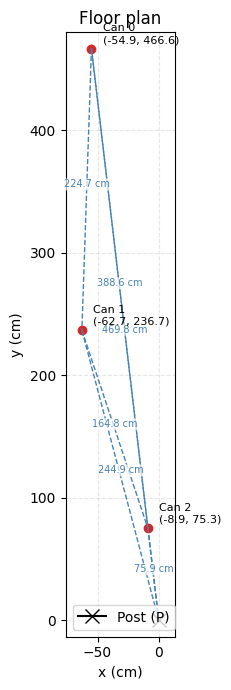

In [4]:
from src.visualise import FloorPlot

FloorPlot(positions).show()